# 01 · O que é engenharia de IA, construindo um modelo de linguagem do zero

> **Capítulo 1 do livro:** *Introduction to Building AI Applications with Foundation Models*.
> Leia o capítulo antes ou depois, este notebook não o substitui: aqui as ideias viram código e exemplos de fábrica.

**Objetivo:** entender, com as próprias mãos, o que um modelo de linguagem faz, por que ele aprende sem rótulos, o que é um token, e como decidir se um problema da fábrica merece uma aplicação de IA.

## Antes de começar

- **Você precisa saber:** Python básico (listas, dicionários, laços).
- **Você não precisa de:** GPU, chave de API, nem saber redes neurais. Tudo aqui roda em segundos num notebook comum.
- **Tempo:** 40 minutos.
- **Como estudar:** em cada "Pare e preveja", escreva sua resposta antes de rodar a célula. Errar a previsão é a parte que ensina.

## Mapa do notebook

1. Um modelo de linguagem é um preditor do próximo pedaço de texto
2. Por que ele aprende sem ninguém rotular nada
3. Gerar texto é sortear, de novo e de novo
4. Tokens: a unidade em que tudo é medido e cobrado
5. Do modelo de linguagem ao modelo de fundação
6. Quando a fábrica deve (e não deve) usar IA generativa
7. As camadas da engenharia de IA

In [1]:
import sys, pathlib, random
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))
%matplotlib inline
import matplotlib.pyplot as plt

## 1. Um modelo de linguagem prevê o próximo pedaço de texto

Vamos trabalhar com um tipo de texto que toda fábrica tem e quase ninguém usa: **as anotações do operador quando a máquina para**. São curtas, repetitivas e cheias de padrão. Este conjunto é sintético (gerado por `aiind/corpus.py`), mas imita o estilo real.

In [2]:
from aiind.corpus import notes
treino = notes(2000, seed=42)     # o que o modelo vai ler
teste  = notes(300,  seed=7)      # texto novo, que ele nunca viu
for t in treino[:8]:
    print("-", t)

- paletizadora parada garra com ruído chamado elétrica
- paletizadora parada para almoço
- enchedora parada bico de enchimento sem leitura
- paletizadora parada cortina de luz sem leitura chamado manutenção
- tampadora parada motor vazando chamado líder motor reapertado
- enchedora parada falta de palete
- rotuladora troca de turno
- enchedora parada vedação com ruído


A ideia central de qualquer modelo de linguagem, do mais simples ao maior que existe, cabe numa frase:

> **Dado o texto até aqui, qual é a probabilidade de cada próximo pedaço?**

O modelo mais simples que faz isso é o **bigrama**: ele conta, no texto de treino, qual palavra veio depois de qual. Nada de rede neural, só contagem. Vamos treinar um.

In [3]:
from aiind.tinylm import NGram, word_tokens
bigrama = NGram(order=2).fit([word_tokens(t) for t in treino])

def top(model, contexto, n=5):
    p = model.next_probs(contexto)
    for tok, prob in sorted(p.items(), key=lambda kv: -kv[1])[:n]:
        print(f"   {tok:22s} {prob:6.1%}")

print("Depois de 'tampadora parada', o modelo espera:")
top(bigrama, ["tampadora", "parada"])

Depois de 'tampadora parada', o modelo espera:
   falta                   19.3%
   sensor                  17.4%
   motor                    6.6%
   garra                    6.3%
   para                     5.6%


### Pare e preveja

O bigrama só olha **uma** palavra para trás. Depois de `"cabeçote"`, o que ele vai prever? E depois de `"parada"`, a lista vai depender de qual máquina parou?

In [4]:
print("Depois de 'cabeçote':"); top(bigrama, ["cabeçote"])
print("\nDepois de 'enchedora parada':"); top(bigrama, ["enchedora", "parada"])
print("\nDepois de 'prensa parada':");    top(bigrama, ["prensa", "parada"])

Depois de 'cabeçote':
   sem                     10.3%
   quebrou                 10.3%
   travou                  10.3%
   limpo                   10.3%
   desalinhado             10.3%

Depois de 'enchedora parada':
   falta                   19.3%
   sensor                  17.4%
   motor                    6.6%
   garra                    6.3%
   para                     5.6%

Depois de 'prensa parada':
   falta                   19.3%
   sensor                  17.4%
   motor                    6.6%
   garra                    6.3%
   para                     5.6%


As duas últimas listas são **idênticas**. O bigrama só enxerga `"parada"` e esquece a máquina. Por isso ele sugere "garra" depois de "prensa parada", uma peça que a prensa não tem.

Essa é a limitação que move toda a história dos modelos de linguagem: **quanto contexto o modelo consegue usar**. O bigrama usa uma palavra. Um trigrama usa duas. Os modelos atuais usam centenas de milhares de tokens, e é aí que mora boa parte do capítulo 2.

## 2. Aprender sem rótulos: autossupervisão

Para treinar um classificador de falhas, alguém precisa rotular milhares de exemplos ("isto é vazamento", "isto é travamento"). Rotular é caro e lento.

Um modelo de linguagem não precisa disso. **O próprio texto é o rótulo**: cada palavra é a resposta certa para o contexto que veio antes dela. Veja quantos exemplos de treino saem de uma única anotação:

In [5]:
frase = "enchedora parada vedação vazando chamado manutenção"
for contexto, alvo in bigrama.training_pairs(word_tokens(frase)):
    print(f"contexto {str(contexto):28s} -> resposta certa: {alvo}")

contexto ('<s>',)                     -> resposta certa: enchedora
contexto ('enchedora',)               -> resposta certa: parada
contexto ('parada',)                  -> resposta certa: vedação
contexto ('vedação',)                 -> resposta certa: vazando
contexto ('vazando',)                 -> resposta certa: chamado
contexto ('chamado',)                 -> resposta certa: manutenção
contexto ('manutenção',)              -> resposta certa: </s>


Uma frase de 6 palavras virou 7 exemplos rotulados, sem nenhum humano. Agora multiplique pela internet inteira: é por isso que modelos de linguagem puderam crescer tanto, enquanto modelos que dependem de rótulos humanos ficaram presos ao tamanho dos conjuntos rotulados.

`<s>` e `</s>` marcam início e fim. Aprender a prever `</s>` é o que ensina o modelo a **parar** de escrever.

### Medindo quão bom é o modelo: perplexidade

Como saber se um modelo aprendeu? Mostramos texto novo e medimos o quanto ele se **surpreende**. A perplexidade é, grosso modo, "entre quantas opções o modelo ficou em dúvida, em média, a cada palavra". Menor é melhor. (O capítulo 3 aprofunda.)

ordem 1 (olha 0 palavra(s) para trás): perplexidade  40.32
ordem 2 (olha 1 palavra(s) para trás): perplexidade   4.34
ordem 3 (olha 2 palavra(s) para trás): perplexidade   3.64


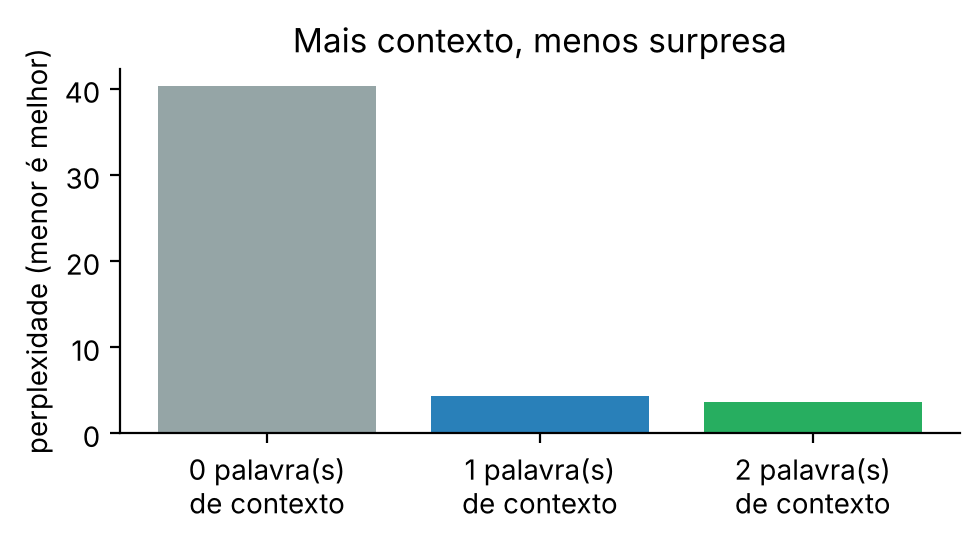

In [6]:
from aiind.tinylm import NGram
seqs_tr = [word_tokens(t) for t in treino]
seqs_te = [word_tokens(t) for t in teste]
ordens, perp = [1, 2, 3], []
for o in ordens:
    m = NGram(order=o).fit(seqs_tr)
    perp.append(m.perplexity(seqs_te))
    print(f"ordem {o} (olha {o-1} palavra(s) para trás): perplexidade {perp[-1]:6.2f}")

fig, ax = plt.subplots(figsize=(5, 2.8))
ax.bar([f"{o-1} palavra(s)\nde contexto" for o in ordens], perp, color=["#95a5a6", "#2980b9", "#27ae60"])
ax.set_ylabel("perplexidade (menor é melhor)"); ax.set_title("Mais contexto, menos surpresa")
ax.spines[["top", "right"]].set_visible(False); plt.tight_layout()

Sem contexto nenhum (ordem 1), o modelo fica em dúvida entre ~40 palavras a cada passo. Com uma palavra de contexto, cai para ~4. Com duas, melhora mais um pouco. **Contexto é o que transforma estatística de palavras em algo que parece entendimento.**

## 3. Gerar texto é sortear o próximo token, repetidamente

Para escrever, o modelo faz o laço: calcula as probabilidades, sorteia um token, junta ao texto, repete até sortear `</s>`. A **temperatura** controla o sorteio:

- **0:** sempre o mais provável. Previsível e repetitivo.
- **1:** sorteia nas proporções aprendidas.
- **acima de 1:** dá chance demais ao improvável. Criativo e cheio de erro.

### Pare e preveja

Com temperatura 0, se gerarmos 5 anotações, quantas serão diferentes entre si?

In [7]:
trigrama = NGram(order=3).fit(seqs_tr)
for temp in (0, 1.0, 3.0):
    rng = random.Random(3)
    print(f"temperatura {temp}:")
    for _ in range(5):
        print("   ", " ".join(trigrama.generate(rng, temperature=temp)))

temperatura 0:
    prensa parada falta de palete
    prensa parada falta de palete
    prensa parada falta de palete
    prensa parada falta de palete
    prensa parada falta de palete
temperatura 1.0:
    tampadora parada garra travou
    paletizadora parada sensor de etiqueta aquecendo de troca formato parada vazando limpo hidráulico rolamento com ruído chamado líder bico de
    paletizadora voltou a operar
    esteira troca de formato
    rotuladora limpeza programada
temperatura 3.0:
    tampadora preventiva enchedora quebrou limpo luz manutenção troca lubrificado de cilindro cola troca formato parada vazando limpo hidráulico rolamento com
    preventiva luz válvula leitura faca chamado hidráulico formato nível palete nível sensor líder esteira aguardando aquecendo palete correia rolo tampadora
    rotuladora parada bobina sem bobina tampa operar leitura leitura presença cabeçote sensor operador cilindro preventiva almoço operador matriz presença vedação
    esteira mangueira ruído

Com temperatura 0, todas iguais: o modelo é **determinístico**. Já com 1.0 aparecem frases que nenhum operador escreveria, com peças de outra máquina e ações sem sentido; com 3.0, piora.

Isso já mostra uma propriedade que vai acompanhar todo o livro: **a saída de um modelo de linguagem é probabilística**. A mesma pergunta pode ter respostas diferentes, e algumas podem ser bem escritas e erradas. Numa fábrica, isso define onde a IA generativa pode ser usada sem revisão humana e onde não pode.

## 4. Tokens: a unidade de tudo

Modelos não leem letras nem palavras: leem **tokens**. Limite de contexto, preço da API e velocidade de resposta são medidos em tokens. Há três formas de cortar texto:

| Tokenizador | Vocabulário | Problema |
|---|---|---|
| caractere | minúsculo (~50) | sequências enormes, cada token diz pouco |
| palavra | gigante, nunca completo | palavra nova vira "desconhecida" |
| subpalavra (BPE) | médio, escolhido | o meio-termo usado pelos modelos atuais |

O **BPE** (*byte-pair encoding*) começa com caracteres e, repetidamente, junta o par mais frequente num token novo. Vamos treinar um com 80 junções:

In [8]:
from aiind.tinylm import BPE, char_tokens
bpe = BPE(merges=80).fit(treino)
print("primeiras junções aprendidas:", [a + b for a, b in bpe.merges[:12]])
print()
for frase in ["tampadora parada cabeçote travou", "robô colaborativo desalinhado"]:
    print(f"{frase!r}\n   -> {bpe.tokens(frase)}")

primeiras junções aprendidas: ['a_', 'ad', 'o_', 'ra_', 'pa', 'en', 'ada_', 'par', 'parada_', 'de', 'ora_', 'am']

'tampadora parada cabeçote travou'
   -> ['tampadora_', 'parada_', 'c', 'a', 'b', 'e', 'ç', 'ot', 'e', '_', 'tr', 'a', 'vo', 'u_']
'robô colaborativo desalinhado'
   -> ['ro', 'b', 'ô', '_', 'co', 'l', 'a', 'b', 'o', 'r', 'a', 'ti', 'v', 'o_', 'de', 's', 'ali', 'n', 'h', 'ado_']


Palavras frequentes no texto de treino (`tampadora`, `parada`) viraram **um token só**. Uma palavra que o modelo nunca viu (`robô colaborativo`) não quebra nada: é decomposta em pedaços menores. É assim que um modelo real lida com nomes de peça e códigos de equipamento que nunca viu.

### Pare e preveja

Para os mesmos 300 textos de teste, ordene do maior para o menor o número de tokens: caracteres, palavras, BPE.

In [9]:
texto = " ".join(teste)
contagem = {"caracteres": len(char_tokens(texto)), "BPE (80 junções)": len(bpe.tokens(texto)), "palavras": len(word_tokens(texto))}
for k, v in contagem.items():
    print(f"{k:18s} {v:6d} tokens")

caracteres          13889 tokens
BPE (80 junções)     5015 tokens
palavras             1851 tokens


O BPE fica no meio. A consequência prática é direta: **um texto em português costuma gastar mais tokens que o mesmo texto em inglês**, porque o vocabulário dos grandes modelos foi aprendido com mais texto em inglês. Mais tokens significa mais custo, mais latência e menos espaço no contexto. Vale lembrar disso ao orçar uma aplicação.

## 5. Do modelo de linguagem ao modelo de fundação

O que fizemos aqui é, em essência, o que um LLM faz, com três diferenças de escala:

| | Nosso trigrama | Um LLM atual |
|---|---|---|
| Como prevê | tabela de contagens | rede neural (transformer) com bilhões de parâmetros |
| Contexto | 2 palavras | de milhares a centenas de milhares de tokens |
| Dados de treino | 2.000 anotações | uma fração enorme do texto público |

Quando o modelo passa a aceitar também imagens, áudio ou vídeo, e serve de base para muitas tarefas diferentes, ele é chamado de **modelo de fundação**. A mudança que o capítulo 1 descreve é esta: antes, cada tarefa exigia treinar um modelo do zero; agora, parte-se de um modelo de fundação pronto e o trabalho passa a ser **adaptá-lo** (com prompt, contexto ou ajuste fino) e **avaliá-lo**. Esse trabalho é a engenharia de IA.

## 6. Quando a fábrica deve usar IA generativa

Tecnologia nova não é motivo. A pergunta certa é: qual o custo de **não** fazer, e qual o custo de a IA errar?

Abaixo, uma matriz simples para comparar ideias. Os critérios e pesos são uma proposta deste repositório, ajuste aos da sua planta.

In [10]:
criterios = {   # peso, e se nota alta é boa (+1) ou ruim (-1)
    "valor se der certo":            (3, +1),
    "custo de um erro":              (3, -1),
    "dados disponíveis":             (2, +1),
    "humano revisa a saída":         (2, +1),
    "dá para medir se funcionou":    (2, +1),
}
ideias = {  # notas de 1 a 5, na ordem dos critérios
    "Assistente que resume anotações de parada do turno": (4, 2, 5, 5, 4),
    "Busca em manuais de manutenção (perguntas e respostas)": (4, 2, 4, 5, 3),
    "Classificar texto livre de parada em código de falha": (5, 3, 5, 3, 5),
    "IA que muda setpoint do CLP sozinha":                 (5, 5, 2, 1, 3),
    "Gerar relatório de OEE em texto para a diretoria":   (2, 2, 5, 5, 3),
}
pesos = [p * s for p, s in criterios.values()]
nota = {k: sum(w * v for w, v in zip(pesos, notas)) for k, notas in ideias.items()}
for k, v in sorted(nota.items(), key=lambda kv: -kv[1]):
    print(f"{v:4d}  {k}")

  34  Assistente que resume anotações de parada do turno
  32  Classificar texto livre de parada em código de falha
  30  Busca em manuais de manutenção (perguntas e respostas)
  26  Gerar relatório de OEE em texto para a diretoria
  12  IA que muda setpoint do CLP sozinha


O resultado conversa com o que o capítulo discute sobre planejamento:

- **No topo:** usos em que um humano revisa e o erro é barato. A IA acelera, a pessoa decide.
- **Embaixo, por bons motivos:** a IA mexendo no processo sozinha. O valor é alto, mas o custo de um erro também é. E, como vimos na seção 3, a saída é probabilística.
- **Classificar parada em código de falha** fica no alto por outro motivo: dá para **medir**, comparando com o que a manutenção registrou. O que se mede, se melhora. Os capítulos 3 e 4 tratam disso.

Antes de começar um projeto, defina também: qual métrica de sucesso, qual o mínimo aceitável para ir para produção, e quem mantém o sistema quando o modelo mudar de versão (e ele vai mudar).

## 7. As camadas da engenharia de IA

Uma forma útil de enxergar o trabalho, em três camadas, de cima para baixo:

| Camada | O que se faz | Exemplo na fábrica |
|---|---|---|
| **Aplicação** | prompt, contexto (RAG), agentes, interface, avaliação | assistente que responde "por que a linha 2 parou ontem?" |
| **Modelo** | ajuste fino, engenharia de dados, otimização de inferência | ajustar um modelo pequeno ao vocabulário da planta |
| **Infraestrutura** | servir o modelo, GPUs, monitoramento, custos | rodar um modelo local num servidor da fábrica, sem dado saindo da rede OT |

Quem vem de **ML clássico** começava pela camada do meio: coletar dados, treinar. Na engenharia de IA, normalmente se **começa pela aplicação**, com um modelo pronto, e só se desce de camada quando a de cima não resolve. Os capítulos 5 e 6 são a camada de aplicação; o 7, o 8 e o 9 descem; o 10 junta tudo.

## Erros comuns

- **Achar que o modelo "sabe" coisas.** Ele estima probabilidades de texto. Uma frase bem escrita pode estar errada, como as peças trocadas entre máquinas da seção 3.
- **Contar palavras em vez de tokens** ao estimar custo e limite de contexto.
- **Escolher o caso de uso pela empolgação.** Comece pelo que um humano revisa e dá para medir.
- **Começar treinando um modelo.** Primeiro teste o que um modelo pronto faz com um bom prompt.
- **Esquecer a manutenção.** Modelos mudam de versão e de preço; o sistema precisa de avaliação contínua.

## Confira o que ficou

**1. Em uma frase, o que um modelo de linguagem faz?**

<details><summary>Ver resposta</summary>

Estima a probabilidade de cada próximo token dado o texto anterior. Gerar texto é sortear dessas probabilidades repetidamente.

</details>

**2. Por que modelos de linguagem puderam ser treinados com muito mais dados que classificadores tradicionais?**

<details><summary>Ver resposta</summary>

Porque são autossupervisionados: o próprio texto fornece o rótulo (o próximo token). Não dependem de pessoas rotulando exemplos.

</details>

**3. O bigrama sugeriu 'garra' depois de 'prensa parada'. Qual é a causa?**

<details><summary>Ver resposta</summary>

Contexto curto demais: ele só enxerga 'parada' e esquece qual máquina parou.

</details>

**4. O que acontece com a saída quando a temperatura é 0?**

<details><summary>Ver resposta</summary>

O modelo sempre escolhe o token mais provável. A saída fica determinística e repetitiva.

</details>

**5. Por que o mesmo texto em português pode custar mais na API que em inglês?**

<details><summary>Ver resposta</summary>

O tokenizador foi aprendido com mais texto em inglês, então o português se quebra em mais tokens, e o preço é por token.

</details>

**6. Qual ideia da matriz tem o maior risco, e por quê?**

<details><summary>Ver resposta</summary>

A IA que muda setpoint do CLP sozinha: o custo de um erro é alto, não há revisão humana e a saída do modelo é probabilística.

</details>

## Exercícios

1. **Contexto:** gere 10 anotações com o bigrama e 10 com o trigrama (temperatura 1). Conte quantas têm uma peça que não pertence à máquina. Qual erra menos?
2. **Dados fora do domínio:** calcule a perplexidade do trigrama em frases que nada têm a ver com fábrica (por exemplo, uma receita de bolo). O que o número diz?
3. **Tokens:** treine o BPE com 20, 80 e 300 junções e veja quantos tokens o conjunto de teste gasta em cada caso. Qual é a troca envolvida?
4. **Sua fábrica:** acrescente à matriz da seção 6 duas ideias de IA da sua realidade e dê as notas. Alguma ficou acima do "resumo de anotações"? Por quê?

## Glossário

- **Token:** pedaço de texto que o modelo lê e gera (pode ser caractere, palavra ou subpalavra).
- **Modelo de linguagem:** modelo que estima a probabilidade do próximo token.
- **Autossupervisão:** aprender com rótulos tirados dos próprios dados.
- **Perplexidade:** quão surpreso o modelo fica com texto novo; menor é melhor.
- **Temperatura:** controla quão arriscado é o sorteio do próximo token.
- **BPE:** tokenizador que junta os pares de símbolos mais frequentes.
- **Modelo de fundação:** modelo grande e geral, que serve de base para muitas tarefas e tipos de dado.
- **Engenharia de IA:** construir aplicações adaptando e avaliando modelos de fundação já treinados.

## Próximo passo

**Notebook 02, capítulo 2 (Understanding Foundation Models):** de onde vêm os dados de treino, o que é um transformer na prática, e como amostragem e saídas estruturadas transformam a anotação livre do operador num JSON que o sistema de OEE consegue usar.